In [2]:
import os
import geopandas as gpd
import pandas as pd
import numpy as np
from scipy.spatial import cKDTree
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
import shap
import matplotlib.pyplot as plt

%matplotlib inline

# Load the 1:1 balanced sample generated in the sampling notebook
sample_path = os.path.join("Datasets", "RZLT_Samples", "RZLT_Balanced_Sample_1to1.geojson")
if not os.path.exists(sample_path):
    sample_path = "RZLT_Balanced_Sample_1to1.geojson"

gdf = gpd.read_file(sample_path)

# Guarantee Irish Transverse Mercator (EPSG:2157) for meter-based spatial math
if gdf.crs != "EPSG:2157":
    gdf = gdf.to_crs(epsg=2157)

print(f"Loaded {len(gdf):,} parcels.")
print(gdf['DECISION_STATUS'].value_counts())

Loaded 1,074 parcels.
DECISION_STATUS
Exclusion    537
Inclusion    537
Name: count, dtype: int64


In [3]:
# Ensure parcel centroids exist in EPSG:2157
if 'centroid_x' not in gdf.columns or 'centroid_y' not in gdf.columns:
    gdf['centroid_x'] = gdf.geometry.centroid.x
    gdf['centroid_y'] = gdf.geometry.centroid.y

parcel_coords = np.column_stack([gdf['centroid_x'], gdf['centroid_y']])

# Toggle to True once you place NTA GTFS 'stops.txt' in your working directory
USE_REAL_GTFS = False
gtfs_stops_path = "gtfs/stops.txt"

if USE_REAL_GTFS and os.path.exists(gtfs_stops_path):
    stops_df = pd.read_csv(gtfs_stops_path)
    stops_gdf = gpd.GeoDataFrame(
        stops_df,
        geometry=gpd.points_from_xy(stops_df['stop_lon'], stops_df['stop_lat']),
        crs="EPSG:4326"
    ).to_crs(epsg=2157)
    stop_coords = np.column_stack([stops_gdf.geometry.x, stops_gdf.geometry.y])
    print(f"Loaded {len(stops_gdf):,} real NTA GTFS transit stops.")
else:
    # Prototype fallback: generate spatial transit nodes across Ireland's ITM bounding box
    np.random.seed(42)
    mock_x = np.random.uniform(gdf['centroid_x'].min(), gdf['centroid_x'].max(), 2500)
    mock_y = np.random.uniform(gdf['centroid_y'].min(), gdf['centroid_y'].max(), 2500)
    stop_coords = np.column_stack([mock_x, mock_y])
    print("Using 2,500 simulated transit stops (set USE_REAL_GTFS = True when stops.txt is ready).")

# Build spatial k-d tree and query nearest neighbor for each parcel
transit_tree = cKDTree(stop_coords)
distances, _ = transit_tree.query(parcel_coords, k=1)

gdf['DISTANCE_TO_TRANSIT'] = distances
# Log-transform skewed continuous features as secondary signals
gdf['LOG_SITE_AREA'] = np.log1p(gdf['SITE_AREA'])

print(f"DISTANCE_TO_TRANSIT summary (meters):")
print(gdf['DISTANCE_TO_TRANSIT'].describe().round(1))

Using 2,500 simulated transit stops (set USE_REAL_GTFS = True when stops.txt is ready).
DISTANCE_TO_TRANSIT summary (meters):
count    1074.0
mean     3014.5
std      1653.2
min       123.5
25%      1643.7
50%      2807.2
75%      4120.0
max      7495.0
Name: DISTANCE_TO_TRANSIT, dtype: float64


In [4]:
# Define continuous numerical features and categorical predictors
num_cols = ['SITE_AREA', 'LOG_SITE_AREA', 'DISTANCE_TO_TRANSIT']
cat_cols = ['ZONE_GZT', 'LOCAL_AUTHORITY']

# Clean categoricals
for col in cat_cols:
    gdf[col] = gdf[col].fillna("Unknown").astype(str).str.strip()

# One-Hot Encode categorical variables
ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
cat_encoded = ohe.fit_transform(gdf[cat_cols])
cat_feature_names = list(ohe.get_feature_names_out(cat_cols))

# Combine numerical and encoded categorical arrays
X_num = gdf[num_cols].values
X = np.hstack([X_num, cat_encoded])
feature_names = num_cols + cat_feature_names
y = gdf['target'].values  # 1 = Inclusion [5, 6], 0 = Exclusion [3, 4]

# Stratified 75/25 Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print(f"Feature matrix shape: {X.shape} ({len(feature_names)} total features)")
print(f"Train samples: {len(X_train)} | Test samples: {len(X_test)}")

Feature matrix shape: (1074, 38) (38 total features)
Train samples: 805 | Test samples: 269


In [5]:
# Initialize classifiers
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

xgb_model = XGBClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.85,
    colsample_bytree=0.85,
    eval_metric='logloss',
    random_state=42
)

# Fit both models
rf_model.fit(X_train, y_train)
xgb_model.fit(X_train, y_train)

# Predict probabilities and binary classes
rf_probs = rf_model.predict_proba(X_test)[:, 1]
xgb_probs = xgb_model.predict_proba(X_test)[:, 1]
xgb_preds = xgb_model.predict(X_test)

print("=== Model Comparison (ROC-AUC) ===")
print(f"Random Forest ROC-AUC: {roc_auc_score(y_test, rf_probs):.4f}")
print(f"XGBoost ROC-AUC:       {roc_auc_score(y_test, xgb_probs):.4f}")

print("\n=== XGBoost Classification Report (0 = Exclusion, 1 = Inclusion) ===")
print(classification_report(y_test, xgb_preds, target_names=['Exclusion (3,4)', 'Inclusion (5,6)']))

=== Model Comparison (ROC-AUC) ===
Random Forest ROC-AUC: 0.9568
XGBoost ROC-AUC:       0.9609

=== XGBoost Classification Report (0 = Exclusion, 1 = Inclusion) ===
                 precision    recall  f1-score   support

Exclusion (3,4)       0.89      0.94      0.92       135
Inclusion (5,6)       0.94      0.89      0.91       134

       accuracy                           0.91       269
      macro avg       0.92      0.91      0.91       269
   weighted avg       0.92      0.91      0.91       269



C:\Users\musab\AppData\Local\Temp\ipykernel_2988\1924117316.py:8: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_test, feature_names=feature_names, max_display=15, show=False)


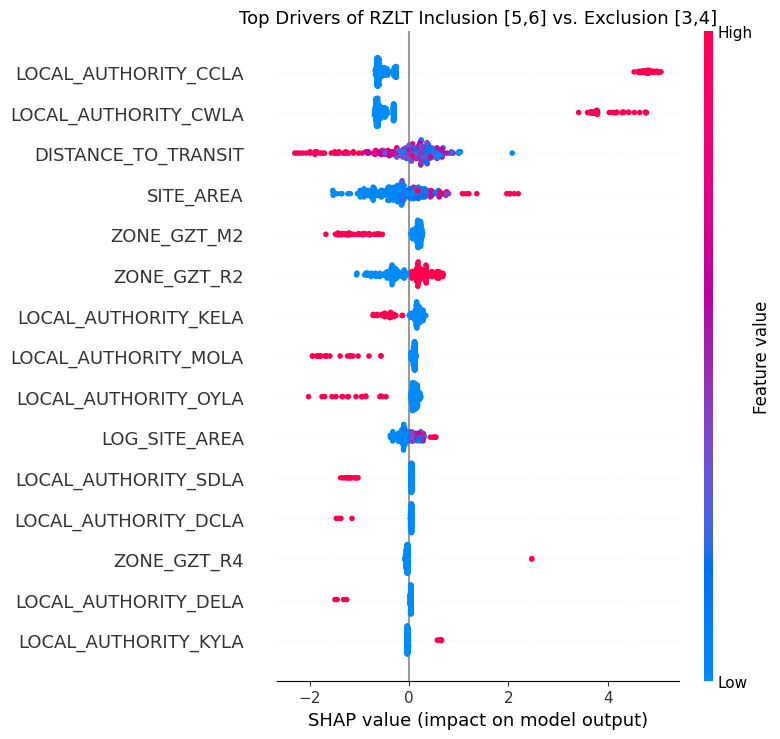

<Figure size 800x500 with 0 Axes>

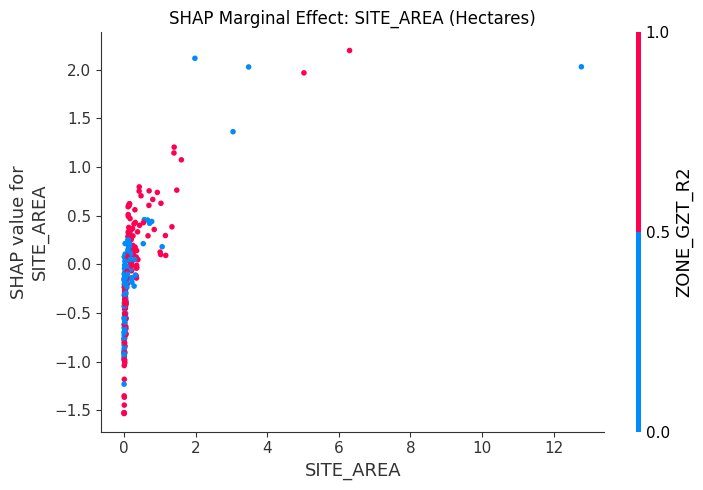

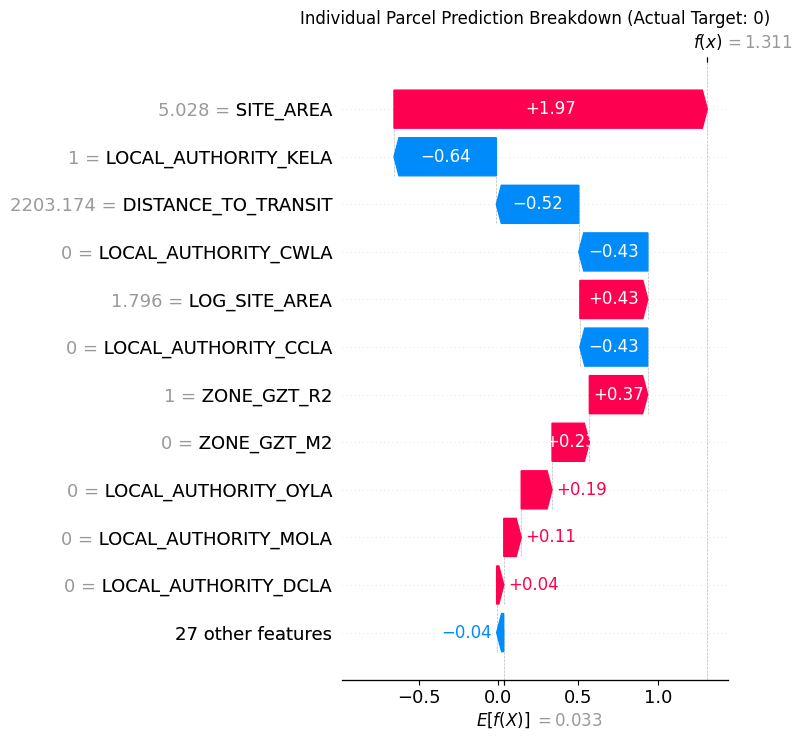

In [6]:
# Compute SHAP values using TreeExplainer on XGBoost
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer(X_test)
shap_values.feature_names = feature_names

# 1. Global Feature Importance Beeswarm Plot
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test, feature_names=feature_names, max_display=15, show=False)
plt.title("Top Drivers of RZLT Inclusion [5,6] vs. Exclusion [3,4]", fontsize=13)
plt.tight_layout()
plt.show()

# 2. Dependence Plot: Parcel Area Impact
plt.figure(figsize=(8, 5))
shap.dependence_plot("SITE_AREA", shap_values.values, X_test, feature_names=feature_names, show=False)
plt.title("SHAP Marginal Effect: SITE_AREA (Hectares)", fontsize=12)
plt.tight_layout()
plt.show()

# 3. Local Waterfall Explanation for Test Sample #0
plt.figure(figsize=(9, 5))
shap.plots.waterfall(shap_values[0], max_display=12, show=False)
plt.title(f"Individual Parcel Prediction Breakdown (Actual Target: {y_test[0]})", fontsize=12)
plt.tight_layout()
plt.show()